In [4]:
import pandas as pd
%matplotlib inline
import matplotlib.pyplot as pl #importa o pacote de plotagem
import matplotlib as mpl
mpl.rcParams['figure.dpi'] = 400
import seaborn as sns
import numpy as np
import plotly.express as px
import scipy.stats as stats
import statsmodels.api as sm
import statsmodels.formula.api as smf
from scipy import stats
from scipy.stats import f_oneway
from statsmodels.formula.api import ols
from statsmodels.stats.anova import anova_lm
from statsmodels.stats.multicomp import pairwise_tukeyhsd
from scipy.stats import friedmanchisquare, wilcoxon
from itertools import combinations
from statsmodels.stats.multitest import multipletests

In [8]:
df_estat_suino_sudeste = pd.read_parquet('C:/Users/thami/OneDrive/Desktop/Projeto PPDI/Dados/tratados/suino_doenças_sudeste.parquet')
df_estat_suino_se_infecto = pd.read_parquet('C:/Users/thami/OneDrive/Desktop/Projeto PPDI/Dados/tratados/suino_doenças_SE_infecto.parquet')
df_estat_suino_abate_sudeste = pd.read_parquet('C:/Users/thami/OneDrive/Desktop/Projeto PPDI/Dados/tratados/suino_abate_SE.parquet')

In [9]:
df_estat_suino_sudeste.groupby(["ANO"], as_index=False)["NUMERO_ANIMAIS_ACOMETIDOS"].sum()

KeyError: 'ANO'

In [10]:
df_estat_suino_sudeste["MES_ANO"] = pd.to_datetime(df_estat_suino_sudeste["MES_ANO"], format="%m/%Y", errors='coerce')
df_estat_suino_sudeste["ANO"] = df_estat_suino_sudeste["MES_ANO"].dt.year
print(df_estat_suino_sudeste.head(3))

     MES_ANO UF_PROCEDENCIA ESPECIE         DIAGNOSTICO  \
0 2022-03-01             MG   Suíno  alteração restrita   
1 2022-05-01             MG   Suíno  alteração restrita   
2 2021-09-01             MG   Suíno  alteração restrita   

   NUMERO_ANIMAIS_ACOMETIDOS   ANO  
0                      67356  2022  
1                      64076  2022  
2                      62306  2021  


In [11]:
df_estat_suino_sudeste = df_estat_suino_sudeste[df_estat_suino_sudeste['ANO'].isin(range(2006, 2027))]
df_estat_suino_abate_sudeste = df_estat_suino_abate_sudeste[df_estat_suino_abate_sudeste['ANO'].isin(range(2006, 2027))]

<h2>Taxas de condenação/abate por estado</h2>

In [12]:
abatidos = (
    df_estat_suino_abate_sudeste.groupby(["UF_PROCEDENCIA"], as_index=False)["QUANTIDADE"]
      .sum()
      .sort_values("QUANTIDADE", ascending=False)
)

condenados = (
    df_estat_suino_sudeste.groupby(["UF_PROCEDENCIA"], as_index=False)["NUMERO_ANIMAIS_ACOMETIDOS"]
      .sum()
      .sort_values("NUMERO_ANIMAIS_ACOMETIDOS", ascending=False)
)

perc_abatidocondenado = round(
    condenados["NUMERO_ANIMAIS_ACOMETIDOS"] /
    abatidos["QUANTIDADE"] * 100, 2
)

tabela_abatidocondenado_estado = pd.DataFrame({
    "UF_PROCEDENCIA": abatidos["UF_PROCEDENCIA"],
    "Abatidos": abatidos["QUANTIDADE"],
    "Condenados": condenados["NUMERO_ANIMAIS_ACOMETIDOS"],
    "Percentual Condenados": perc_abatidocondenado
})

tabela_abatidocondenado_estado

,UF_PROCEDENCIA,Abatidos,Condenados,Percentual Condenados
1,MG,47502462,5119785,10.78
3,SP,13683626,1631317,11.92
2,RJ,24881,11889,47.78
0,ES,942,1070,113.59


<h2>Taxas de condenação/abate por ano</h2>

In [13]:
# 1. Agrupa cada base por ANO (garantindo que ANO seja inteiro)
abatidos = (
    df_estat_suino_abate_sudeste
    .groupby("ANO", as_index=False)["QUANTIDADE"]
    .sum()
    .rename(columns={"QUANTIDADE": "Abatidos"})
)
abatidos["ANO"] = abatidos["ANO"].astype(int)

condenados = (
    df_estat_suino_sudeste
    .groupby("ANO", as_index=False)["NUMERO_ANIMAIS_ACOMETIDOS"]
    .sum()
    .rename(columns={"NUMERO_ANIMAIS_ACOMETIDOS": "Condenados"})
)
condenados["ANO"] = condenados["ANO"].astype(int)

# 2. Une as duas tabelas cruzando exatamente pela coluna ANO
# Use how="inner" para manter apenas os anos que existem nas DUAS bases,
# ou how="left" se quiser manter todos os anos de abate (2006 a 2024)
tabela_abatidocondenado_ano = (
    abatidos.merge(condenados, on="ANO", how="inner")
    .sort_values("ANO")
    .reset_index(drop=True)
)

# 3. Calcula o percentual com as colunas já perfeitamente alinhadas
tabela_abatidocondenado_ano["Percentual Condenados"] = round(
    (tabela_abatidocondenado_ano["Condenados"] / tabela_abatidocondenado_ano["Abatidos"]) * 100,
    2
)

tabela_abatidocondenado_ano

,ANO,Abatidos,Condenados,Percentual Condenados
0,2021,5536619,1367224,24.69
1,2022,5839350,1603016,27.45
2,2023,5480206,1334545,24.35
3,2024,5223147,1137364,21.78
4,2025,5306759,1080545,20.36
5,2026,1201571,241367,20.09


<h2>Taxas de condenação/abate por estado</h2>
<h3>Qual estado teve a maior taxa com base no total de abate</h3>

In [14]:
abatidos = (
    df_estat_suino_abate_sudeste
    .groupby("UF_PROCEDENCIA", as_index=False)["QUANTIDADE"]
    .sum()
    .rename(columns={"QUANTIDADE": "Abatidos"})
)

condenados = (
    df_estat_suino_sudeste
    .groupby("UF_PROCEDENCIA", as_index=False)["NUMERO_ANIMAIS_ACOMETIDOS"]
    .sum()
    .rename(columns={"NUMERO_ANIMAIS_ACOMETIDOS": "Condenados"})
)

# 2. Une as duas tabelas cruzando exatamente pela coluna ANO
# Use how="inner" para manter apenas os anos que existem nas DUAS bases,
# ou how="left" se quiser manter todos os anos de abate (2006 a 2024)
tabela_abatidocondenado_ano = (
    abatidos.merge(condenados, on="UF_PROCEDENCIA", how="inner")
    .sort_values("UF_PROCEDENCIA")
    .reset_index(drop=True)
)

# 3. Calcula o percentual com as colunas já perfeitamente alinhadas
tabela_abatidocondenado_ano["Percentual Condenados"] = round(
    (tabela_abatidocondenado_ano["Condenados"] / tabela_abatidocondenado_ano["Abatidos"]) * 100,
    2
)

tabela_abatidocondenado_ano

,UF_PROCEDENCIA,Abatidos,Condenados,Percentual Condenados
0,ES,942,1070,113.59
1,MG,47502462,5119785,10.78
2,RJ,24881,11889,47.78
3,SP,13683626,1631317,11.92


<h2>Taxas de condenação/abate por ano</h2>
<h3>Qual ano teve a maior taxa com base no total de abate</h3>

In [15]:
abatidos = (
    df_estat_suino_abate_sudeste
    .groupby("ANO", as_index=False)["QUANTIDADE"]
    .sum()
    .rename(columns={"QUANTIDADE": "Abatidos"})
)
abatidos["ANO"] = abatidos["ANO"].astype(int)

condenados = (
    df_estat_suino_sudeste
    .groupby("ANO", as_index=False)["NUMERO_ANIMAIS_ACOMETIDOS"]
    .sum()
    .rename(columns={"NUMERO_ANIMAIS_ACOMETIDOS": "Condenados"})
)
condenados["ANO"] = condenados["ANO"].astype(int)

# 2. Une as duas tabelas cruzando exatamente pela coluna ANO
# Use how="inner" para manter apenas os anos que existem nas DUAS bases,
# ou how="left" se quiser manter todos os anos de abate (2006 a 2024)
tabela_abatidocondenado_ano = (
    abatidos.merge(condenados, on="ANO", how="inner")
    .sort_values("ANO")
    .reset_index(drop=True)
)

# 3. Calcula o percentual com as colunas já perfeitamente alinhadas
tabela_abatidocondenado_ano["Percentual Condenados"] = round(
    (tabela_abatidocondenado_ano["Condenados"] / tabela_abatidocondenado_ano["Abatidos"]) * 100,
    2
)

tabela_abatidocondenado_ano

,ANO,Abatidos,Condenados,Percentual Condenados
0,2021,5536619,1367224,24.69
1,2022,5839350,1603016,27.45
2,2023,5480206,1334545,24.35
3,2024,5223147,1137364,21.78
4,2025,5306759,1080545,20.36
5,2026,1201571,241367,20.09


<h3>Teste anova e tukey<h3>

In [16]:
condenacao_consolidado = df_estat_suino_sudeste.groupby(['ANO', 'UF_PROCEDENCIA'], as_index=False).agg(CONDENADO=("NUMERO_ANIMAIS_ACOMETIDOS", "sum"))
condenacao_consolidado

,ANO,UF_PROCEDENCIA,CONDENADO
0,2021,ES,136
1,2021,MG,1158824
2,2021,RJ,2531
3,2021,SP,205733
4,2022,ES,65
5,2022,MG,1319996
6,2022,RJ,3873
7,2022,SP,279082
8,2023,ES,653
9,2023,MG,962669


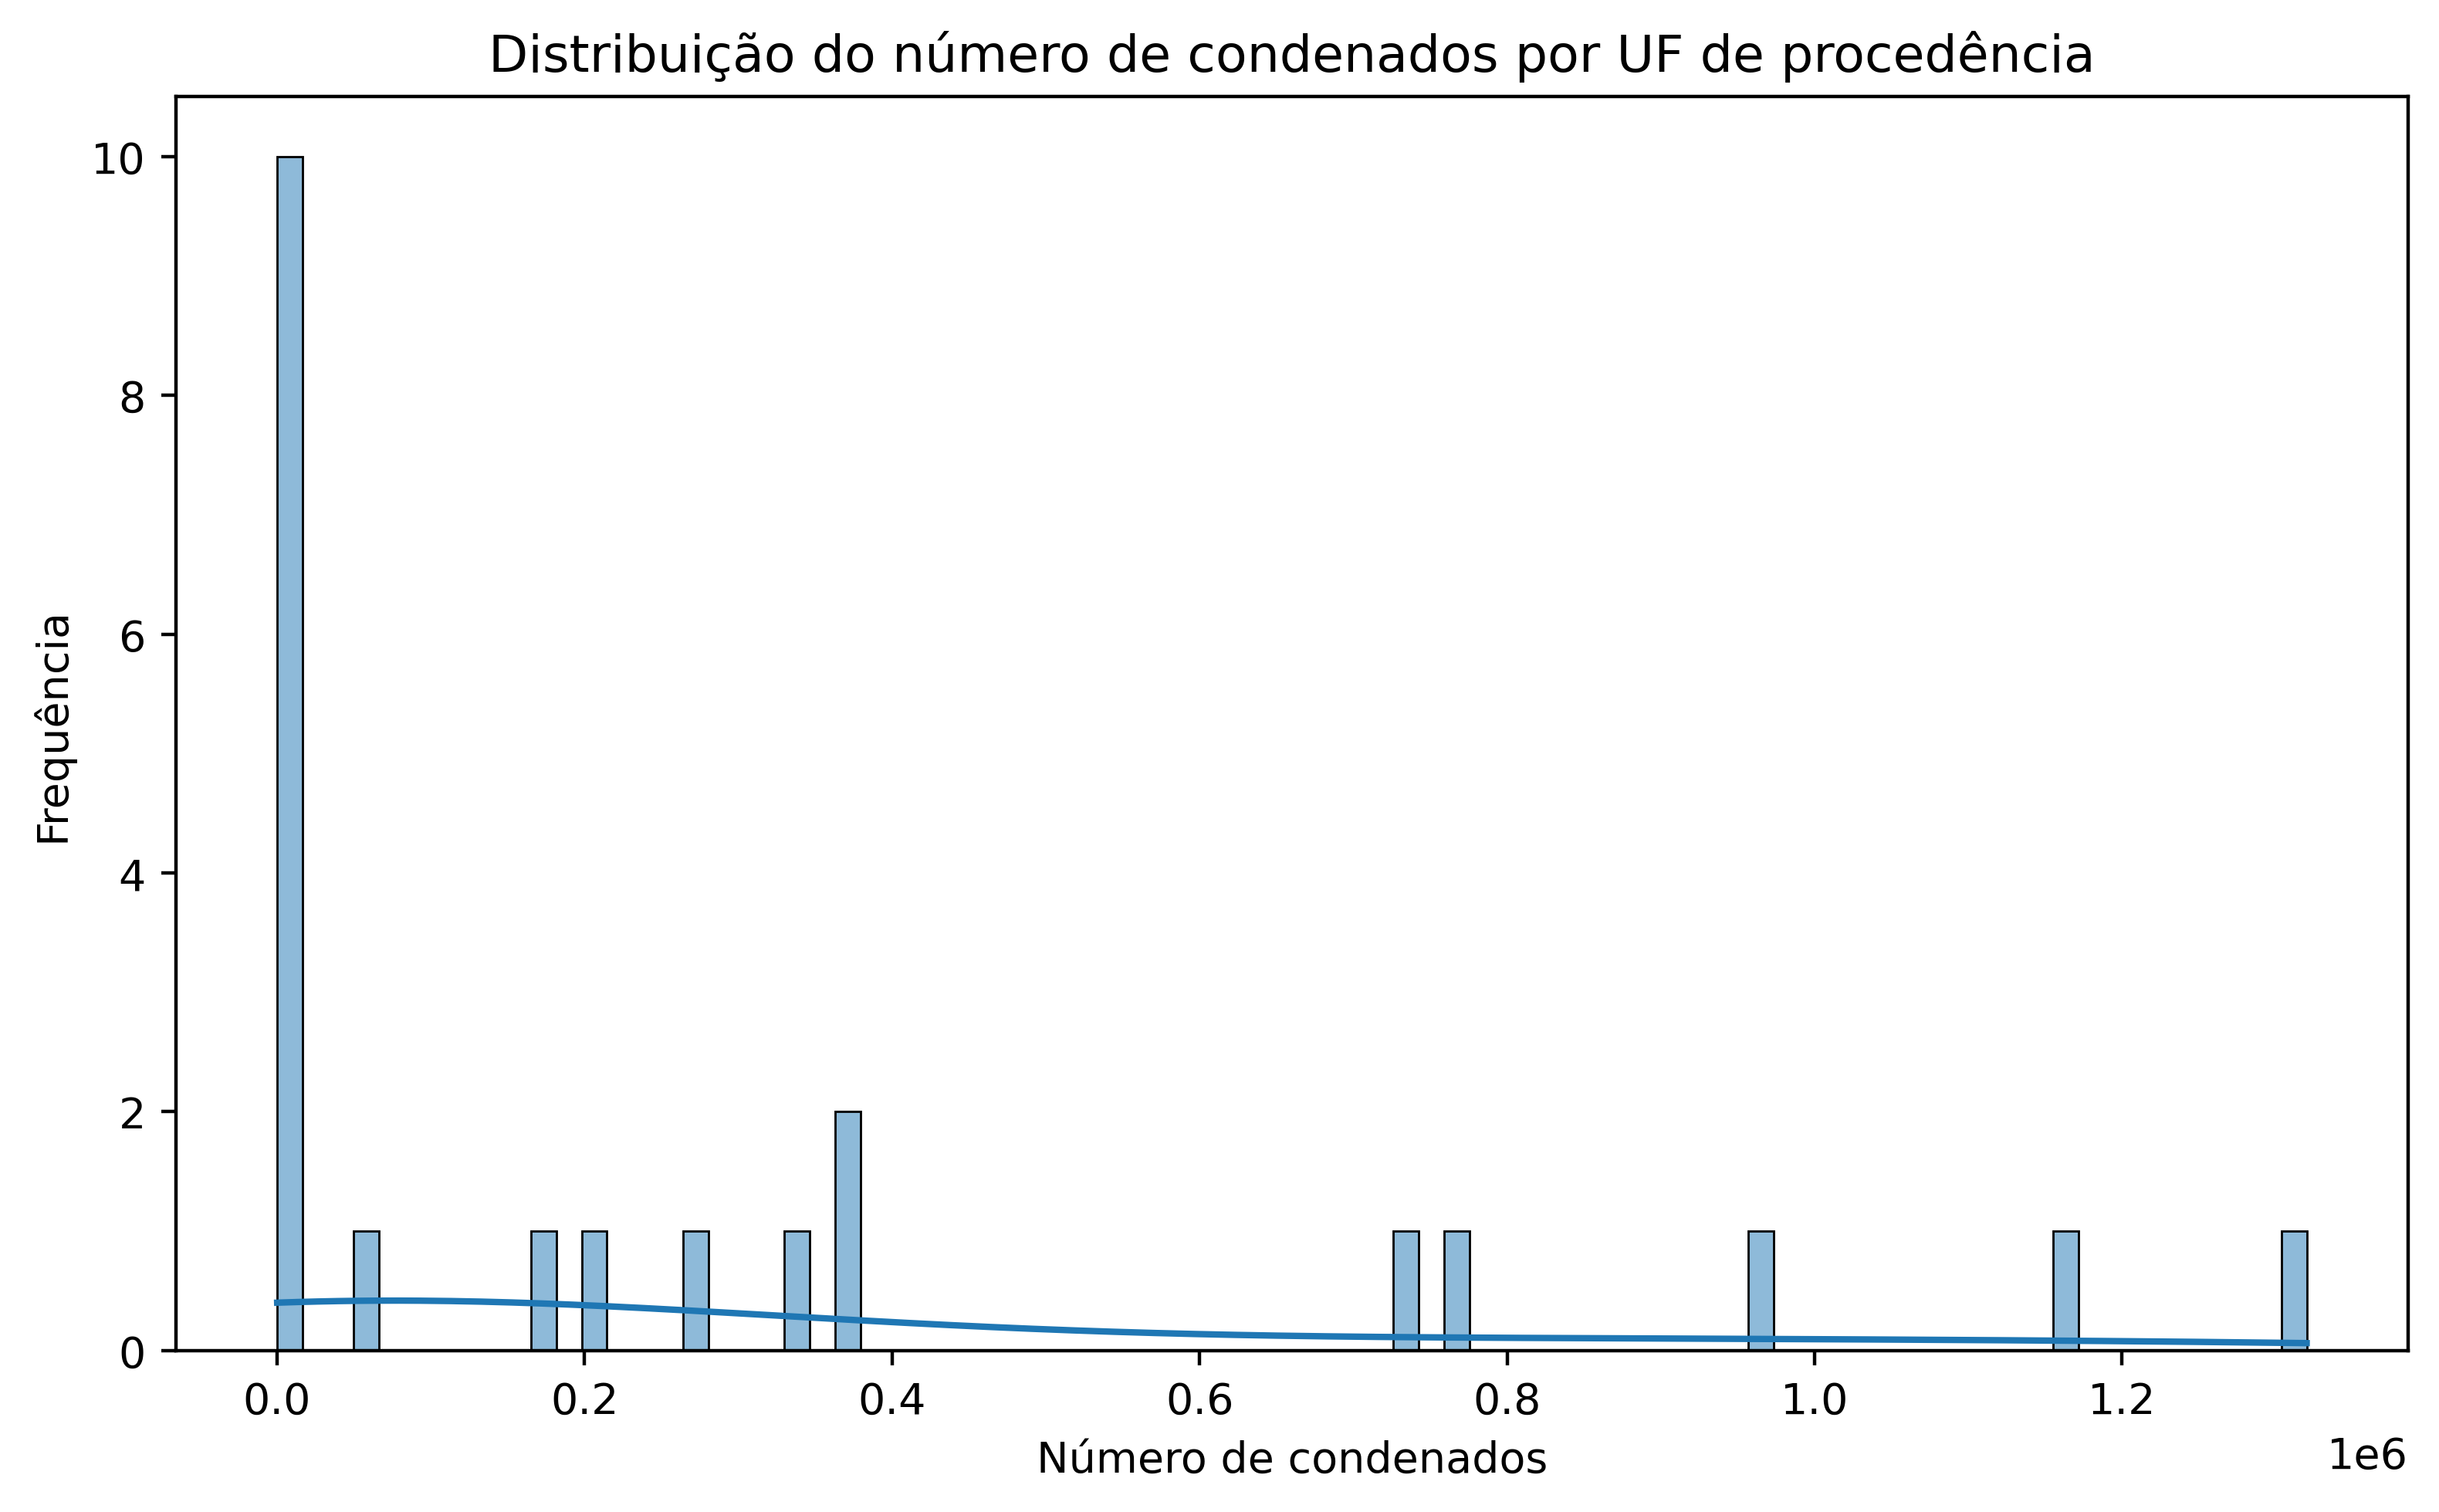

In [21]:
pl.figure(figsize=(8, 5))

sns.histplot(
    data=condenacao_consolidado,
    x="CONDENADO",
    bins=80,
    kde=True
)

pl.title("Distribuição do número de condenados por UF de procedência")
pl.xlabel("Número de condenados")
pl.ylabel("Frequência")
pl.tight_layout()
pl.show()

In [17]:
abate_consolidado = df_estat_suino_abate_sudeste.groupby(['ANO', 'UF_PROCEDENCIA'], as_index=False).agg(ABATE=("QUANTIDADE", "sum"))
abate_consolidado

,ANO,UF_PROCEDENCIA,ABATE
0,2006,MG,991779
1,2006,SP,178474
2,2007,MG,1048410
3,2007,SP,105247
4,2008,MG,1140189
5,2008,SP,79578
6,2009,MG,1266071
7,2009,SP,111161
8,2010,MG,1543581
9,2010,SP,194292


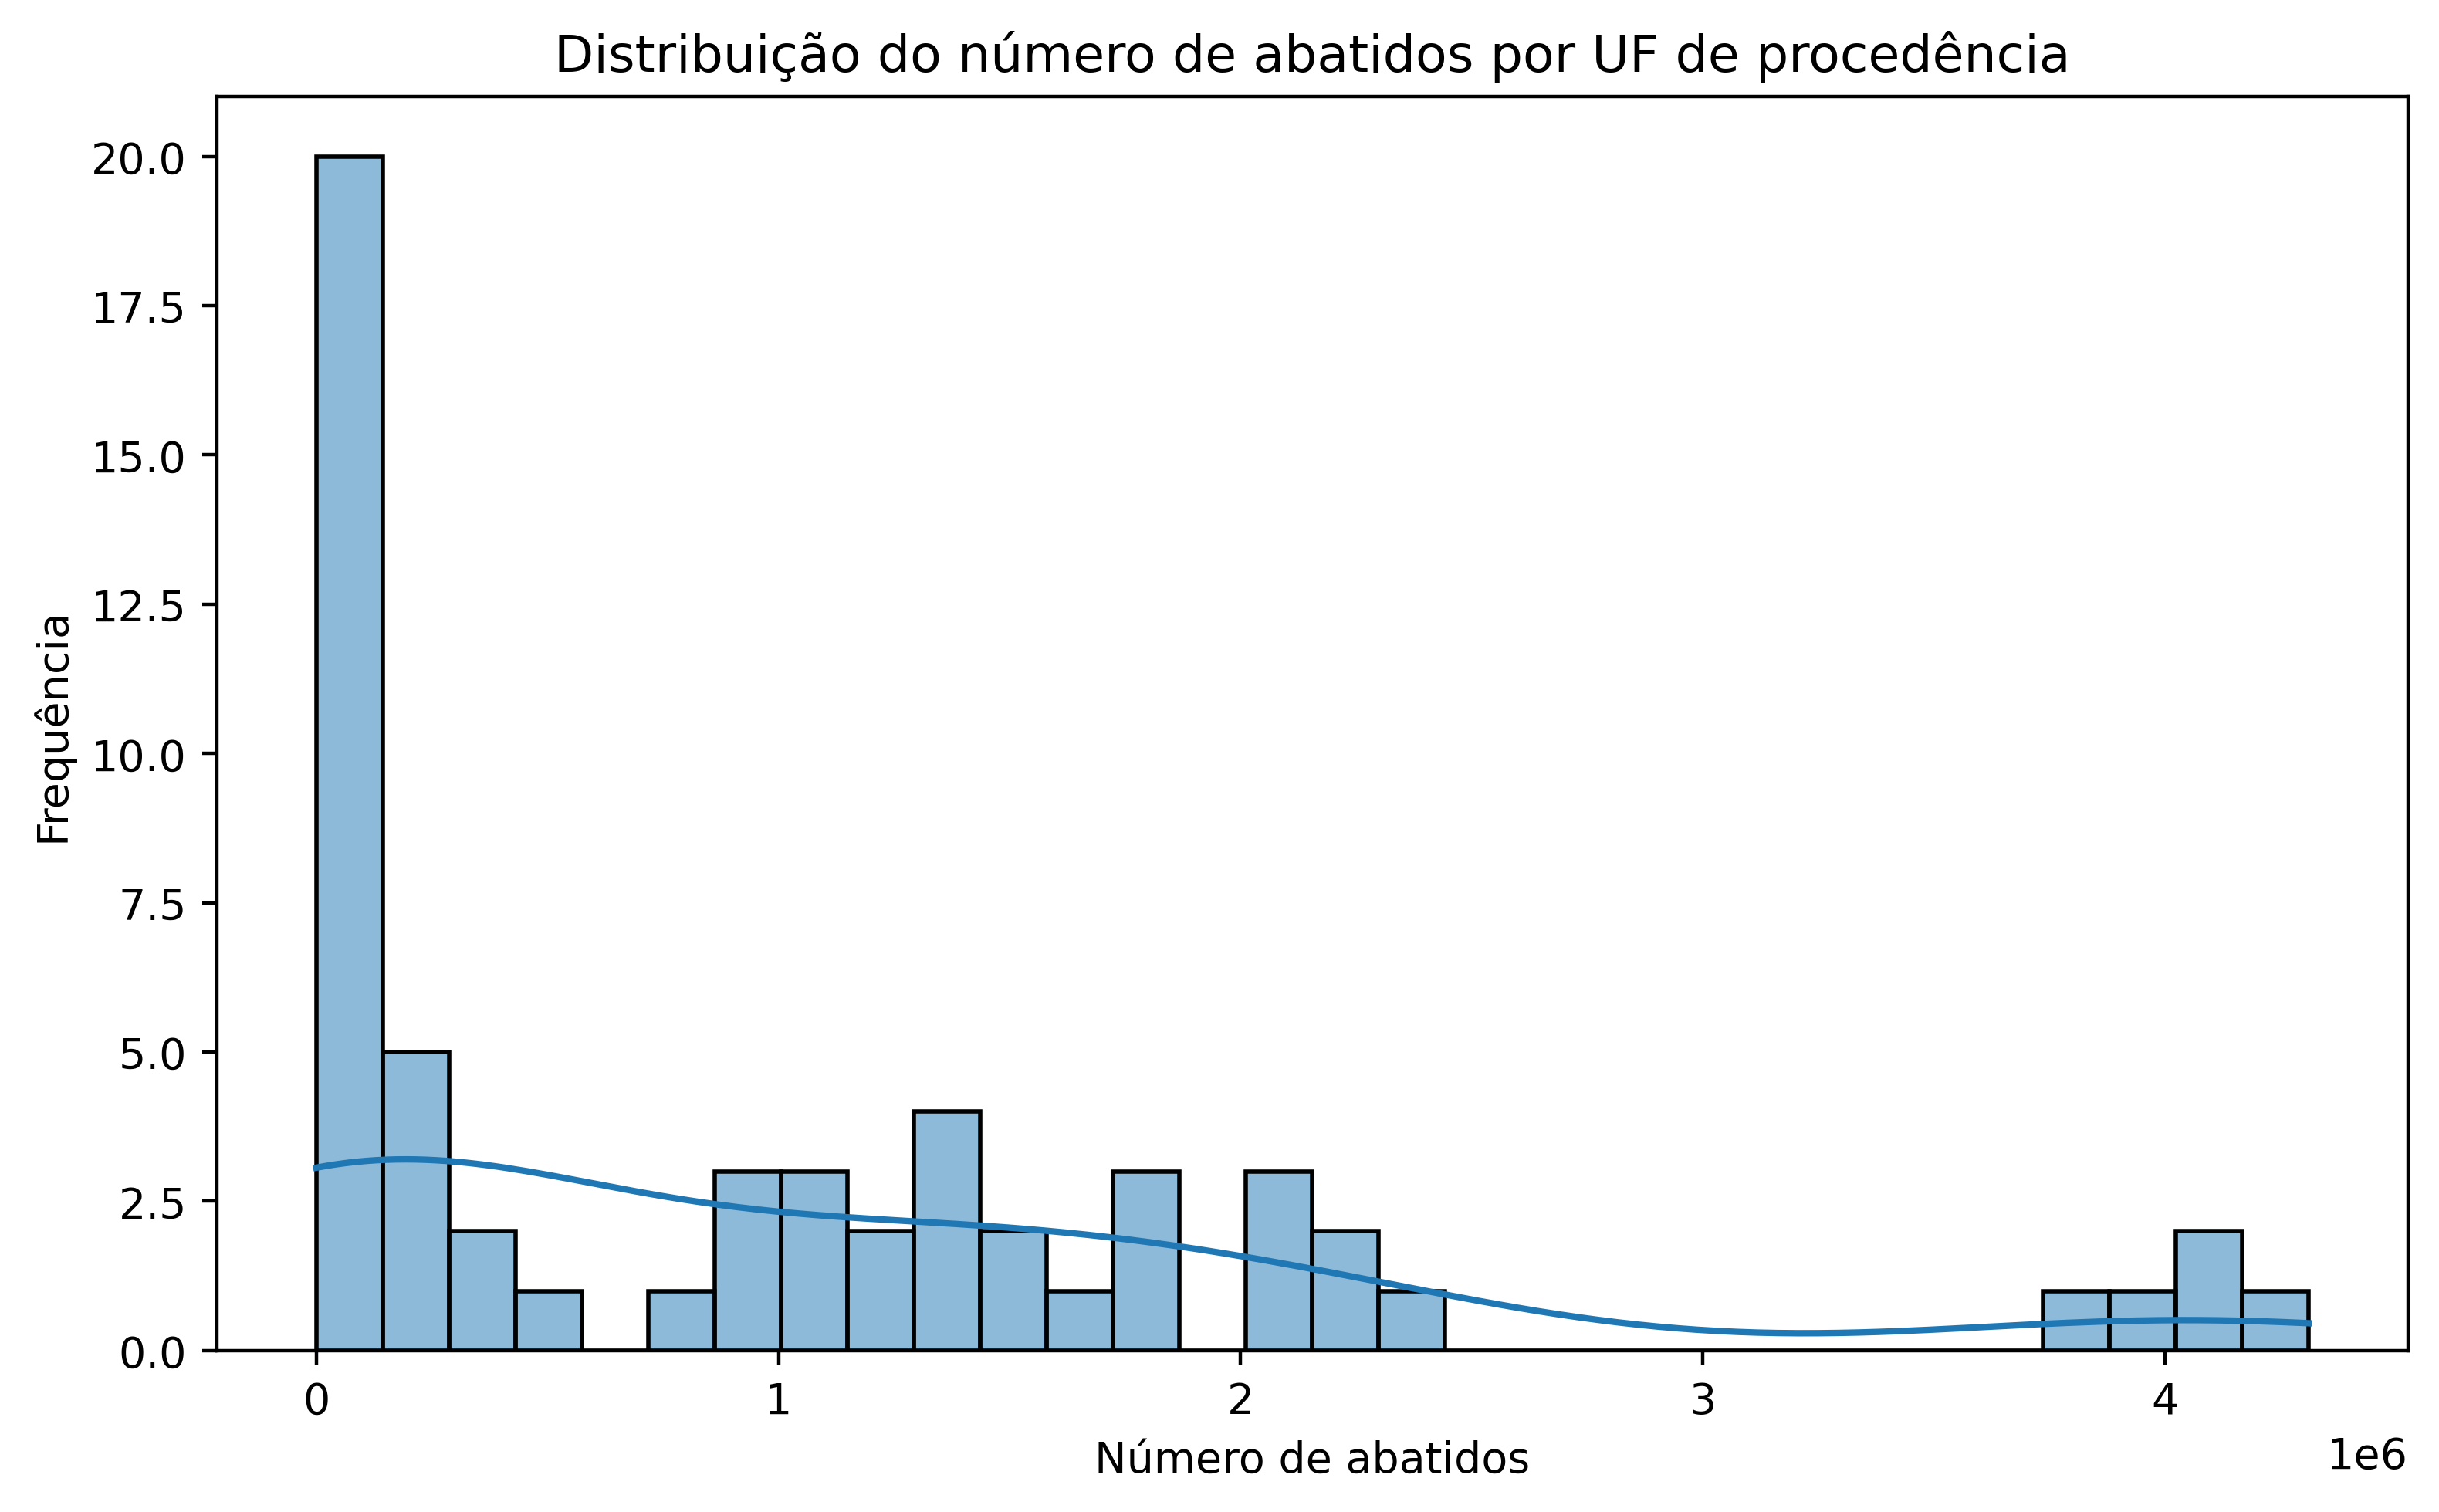

In [23]:
pl.figure(figsize=(8, 5))

sns.histplot(
    data=abate_consolidado,
    x="ABATE",
    bins=30,
    kde=True
)

pl.title("Distribuição do número de abatidos por UF de procedência")
pl.xlabel("Número de abatidos")
pl.ylabel("Frequência")
pl.tight_layout()
pl.show()

In [18]:
# 1. Garante padronização das chaves antes de cruzar
for df in [condenacao_consolidado, abate_consolidado]:
    df["ANO"] = df["ANO"].astype(int)
    df["UF_PROCEDENCIA"] = df["UF_PROCEDENCIA"].astype(str).str.strip().str.upper()

# 2. Usa how='inner' para não transformar anos sem base de condenação em 0% falso
dados_anova = pd.merge(
    condenacao_consolidado,
    abate_consolidado,
    on=["ANO", "UF_PROCEDENCIA"],
    how="inner",
    validate="one_to_one"
)

# 3. Remove eventuais registros com abate zerado para evitar divisão por zero (inf)
dados_anova = dados_anova[dados_anova["ABATE"] > 0].copy()

# 4. Preenche nulos e calcula o percentual
dados_anova["CONDENADO"] = dados_anova["CONDENADO"].fillna(0)
dados_anova["percentual_condenados"] = (
    dados_anova["CONDENADO"] / dados_anova["ABATE"] * 100
).round(4)

# 5. Organiza a ordem das colunas e ordena por Ano e UF
colunas_ordenadas = ["ANO", "UF_PROCEDENCIA", "ABATE", "CONDENADO", "percentual_condenados"]
dados_anova = (
    dados_anova[colunas_ordenadas]
    .sort_values(["ANO", "UF_PROCEDENCIA"])
    .reset_index(drop=True)
)

print(dados_anova.head(100))
dados_anova.to_excel("tabela_dadosanova.xlsx", index=False)

     ANO UF_PROCEDENCIA    ABATE  CONDENADO  percentual_condenados
0   2021             ES      159        136                85.5346
1   2021             MG  4158031    1158824                27.8695
2   2021             RJ     2604       2531                97.1966
3   2021             SP  1375825     205733                14.9534
4   2022             ES       37         65               175.6757
5   2022             MG  4310971    1319996                30.6195
6   2022             RJ     3481       3873               111.2611
7   2022             SP  1524861     279082                18.3021
8   2023             ES      457        653               142.8884
9   2023             MG  4065045     962669                23.6816
10  2023             RJ     3587       1054                29.3839
11  2023             SP  1411117     370169                26.2323
12  2024             ES       99         27                27.2727
13  2024             MG  3831368     759571                19.

In [19]:
grupos = [
    grupo["percentual_condenados"].dropna()
    for _, grupo in dados_anova.groupby("UF_PROCEDENCIA")
]

In [20]:
f_stat, p_value = stats.f_oneway(*grupos)
print("F =", f_stat)
print("p =", p_value)

F = 10.586194426842846
p = 0.00030691154242480927


In [21]:
modelo = ols('percentual_condenados ~ C(UF_PROCEDENCIA)', data=dados_anova).fit()
anova_tabela = sm.stats.anova_lm(modelo, typ=2)
print(anova_tabela)

TypeError: Cannot interpret '<StringDtype(na_value=nan)>' as a data type

In [22]:
grupos_A = [
    grupo["percentual_condenados"].dropna()
    for _, grupo in dados_anova.groupby("ANO")
]

In [23]:
f_stat, p_value = stats.f_oneway(*grupos_A)
print("F =", f_stat)
print("p =", p_value)

F = 0.4773338860263038
p = 0.7879292643572262


In [24]:
modelo = ols('percentual_condenados ~ C(ANO) + C(UF_PROCEDENCIA)', data=dados_anova).fit()
anova_tabela = sm.stats.anova_lm(modelo, typ=2)
print(anova_tabela)

TypeError: Cannot interpret '<StringDtype(na_value=nan)>' as a data type

In [25]:
tukey = pairwise_tukeyhsd(
    endog=dados_anova["percentual_condenados"],
    groups=dados_anova["UF_PROCEDENCIA"],
    alpha=0.05
)
print(tukey.summary())

  Multiple Comparison of Means - Tukey HSD, FWER=0.05  
group1 group2 meandiff p-adj    lower    upper   reject
-------------------------------------------------------
    ES     MG -82.8046  0.002 -136.6999 -28.9092   True
    ES     RJ -16.3382 0.8441  -72.6301  39.9537  False
    ES     SP -83.8843 0.0018 -137.7797 -29.9889   True
    MG     RJ  66.4664 0.0128    12.571 120.3618   True
    MG     SP  -1.0798 0.9999   -52.467  50.3075  False
    RJ     SP -67.5461 0.0114 -121.4415 -13.6508   True
-------------------------------------------------------


In [26]:
import statsmodels.api as sm
import statsmodels.formula.api as smf
from scipy import stats

modelo = smf.ols("percentual_condenados ~ C(UF_PROCEDENCIA) + C(ANO)", data=dados_anova).fit()

# 1. Normalidade dos resíduos (Shapiro-Wilk: ideal p > 0.05)
stat_sw, p_sw = stats.shapiro(modelo.resid)

# 2. Homogeneidade de variâncias entre UFs (Levene: ideal p > 0.05)
grupos_uf = [g["percentual_condenados"].values for _, g in dados_anova.groupby("UF_PROCEDENCIA")]
stat_lev, p_lev = stats.levene(*grupos_uf)

# 3. Alternativa não paramétrica (Kruskal-Wallis) caso Shapiro ou Levene dê p < 0.05
stat_kw, p_kw = stats.kruskal(*grupos_uf)

print(f"Shapiro-Wilk p = {p_sw:.4f} | Levene p = {p_lev:.4f} | Kruskal-Wallis p = {p_kw:.4f}")

TypeError: Cannot interpret '<StringDtype(na_value=nan)>' as a data type

In [2]:
%pip install pingouin

  Using cached pingouin-0.7.0-py3-none-any.whl.metadata (19 kB)
  Using cached pandas_flavor-0.8.1-py3-none-any.whl.metadata (6.6 kB)
Using cached pingouin-0.7.0-py3-none-any.whl (206 kB)
   ---------------------------------------- 0.0/9.3 MB ? eta -:--:--
   ---------------- ----------------------- 3.9/9.3 MB 22.7 MB/s eta 0:00:01
   ---------------------------------------  9.2/9.3 MB 24.2 MB/s eta 0:00:01
   ---------------------------------------- 9.3/9.3 MB 22.2 MB/s eta 0:00:00
   ---------------------------------------- 0.0/10.7 MB ? eta -:--:--
   ---------------------------- ----------- 7.6/10.7 MB 37.6 MB/s eta 0:00:01
   ---------------------------------------- 10.7/10.7 MB 32.7 MB/s eta 0:00:00
Using cached pandas_flavor-0.8.1-py3-none-any.whl (8.5 kB)

  Attempting uninstall: pandas

    Found existing installation: pandas 2.2.3

   ---------------------------------------- 0/4 [pandas]
   ---------------------------------------- 0/4 [pandas]
   -----------------------------

ERROR: pip's dependency resolver does not currently take into account all the packages that are installed. This behaviour is the source of the following dependency conflicts.
streamlit 1.45.1 requires pandas<3,>=1.4.0, but you have pandas 3.1.1 which is incompatible.


In [28]:
import pingouin as pg

# Games-Howell: substituto ideal do Tukey quando Levene dá p < 0.05
gh = pg.pairwise_gameshowell(
    dv="percentual_condenados",
    between="UF_PROCEDENCIA",
    data=dados_anova
)

# Imprime todas as colunas já calculadas pelo Pingouin (A, B, mean_A, mean_B, diff, se, T, df, pval, hedges)
gh

,A,B,mean_A,mean_B,diff,se,T,df,pval,hedges
0,ES,MG,106.169020,23.364467,82.804553,25.452021,3.253359,4.050598,0.097764,1.992229
1,ES,RJ,106.169020,89.830860,16.338160,29.679249,0.550491,6.594751,0.943335,0.314468
2,ES,SP,106.169020,22.284717,83.884303,25.445499,3.296626,4.046468,0.094173,2.018981
3,MG,RJ,23.364467,89.830860,-66.466393,15.530307,-4.279786,4.137484,0.040081,-2.613884
4,MG,SP,23.364467,22.284717,1.079750,2.793934,0.386462,9.981947,0.979296,0.205961
5,RJ,SP,89.830860,22.284717,67.546143,15.519616,4.352308,4.126254,0.038056,2.659070
